In [5]:
%tensorflow_version 2.x
import tensorflow as tf
from tensorflow import keras

import numpy as np
import matplotlib.pyplot as plt




Colab only includes TensorFlow 2.x; %tensorflow_version has no effect.


In [6]:
fashion_mnist = keras.datasets.fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()



29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [8]:
train_images.shape

(60000, 28, 28)

In [9]:
train_images[0,23,23]

np.uint8(194)

In [10]:
train_labels[:10]

array([9, 0, 0, 3, 0, 2, 7, 2, 5, 5], dtype=uint8)

In [11]:
class_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal',
               'Shirt','Sneaker','Bag','Ankle boot']

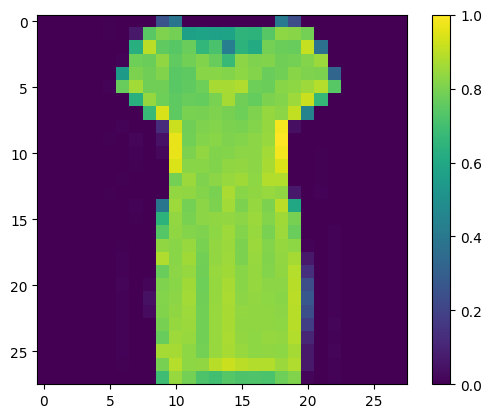

In [29]:
plt.figure()
plt.imshow(train_images[20])
plt.colorbar()
plt.grid(False)
plt.show()

In [17]:
train_images = train_images/255.0
test_images = test_images/255.0

In [18]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28,28)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [19]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

In [21]:
model.fit(train_images, train_labels, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8238 - loss: 0.5004
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8650 - loss: 0.3764
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8762 - loss: 0.3385
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8851 - loss: 0.3134
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8905 - loss: 0.2962
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8962 - loss: 0.2811
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9006 - loss: 0.2671
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9046 - loss: 0.2553
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9072 - loss: 0.2465
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9115 - loss: 0.2373


In [22]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=1)
print(test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8776 - loss: 0.3523
0.8776000142097473


In [23]:
test_images.shape

(10000, 28, 28)

In [24]:
predictions = model.predict(test_images)
print(predictions)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
[[6.2629034e-08 5.0080907e-12 1.0969986e-09 ... 2.1590516e-02
  7.4324042e-08 9.7689629e-01]
 [2.3431568e-05 3.6058593e-12 9.9938613e-01 ... 8.1305009e-16
  1.3381055e-10 2.1273066e-14]
 [9.5591545e-08 9.9999982e-01 6.6873840e-11 ... 1.2963789e-22
  2.5985968e-14 4.2940538e-19]
 ...
 [1.0494879e-05 4.7417161e-12 1.4372348e-05 ... 2.3796417e-08
  9.9990958e-01 1.6509158e-12]
 [7.8270705e-09 9.9996608e-01 1.7121728e-09 ... 2.7183494e-12
  3.2600447e-10 1.7552808e-10]
 [1.8931867e-05 1.8123996e-09 5.1630786e-06 ... 2.6176006e-02
  5.4128446e-05 8.5474865e-05]]


In [30]:
print(class_names[np.argmax(predictions[20])])

Pullover
